<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">

# Procesamiento de Lenguaje Natural I
## Desafío 2 - Custom embeddings con Gensim

### Objetivo

El objetivo de este desafío es crear embeddings de palabras propios a partir de un corpus de texto, utilizando `gensim` y el modelo `Word2Vec`. De esta forma los vectores obtenidos capturarán la forma en la que esas palabras se usan dentro del corpus elegido.

Como corpus se utiliza el texto completo de **La Odisea**, de Homero, en la traducción al español de Luis Segalá y Estalella, obtenido de **Project Gutenberg** (obra de dominio público): https://www.gutenberg.org/ebooks/58221

Se eligió un libro completo porque es un corpus mucho más extenso y con oraciones gramaticalmente completas, lo que debería traducirse en embeddings menos ruidosos que los que se obtienen con corpus chicos, como el visto como ejemplo en clases.

In [30]:
import os
import re
import numpy as np
import pandas as pd
import urllib.request

import matplotlib.pyplot as plt
import seaborn as sns

try:
    from gensim.models import Word2Vec
except ImportError:
    %pip install -q gensim
    from gensim.models import Word2Vec

### Datos

In [31]:
# Descargamos el texto plano (UTF-8) de "La Odisea" desde Project Gutenberg.
# Es una obra de dominio público, por lo que su uso como corpus de entrenamiento no tiene restricciones.
BOOK_URL = "https://www.gutenberg.org/ebooks/58221.txt.utf-8"
RAW_PATH = "odisea_raw.txt"

if not os.path.exists(RAW_PATH):
    urllib.request.urlretrieve(BOOK_URL, RAW_PATH)

with open(RAW_PATH, encoding="utf-8") as fp:
    raw_text = fp.read()

print("Caracteres descargados:", len(raw_text))

Caracteres descargados: 1001683


### 1 - Preprocesamiento

Project Gutenberg agrega al principio y al final de cada libro una cabecera/pie legal con la licencia, y este libro en particular incluye además, después del Canto XXIV, un extenso índice de nombres propios. Ninguna de esas secciones forma parte del relato, así que las descartamos y nos quedamos solo con el cuerpo narrativo (del "Canto Primero" al final del "Canto XXIV").

También limpiamos algunos elementos propios de la edición de Gutenberg que no aportan al contenido semántico del relato: los pies de las ilustraciones (`[Ilustración: ...]`), los encabezados de cada canto en mayúsculas sostenidas, y la numeración de versos que antecede a cada párrafo (por ejemplo, `"492 Tal dijo..."`).

In [32]:
start = raw_text.find("CANTO PRIMERO")
end = raw_text.find("ÍNDICE DE NOMBRES PROPIOS")
assert start != -1 and end != -1 and end > start

body = raw_text[start:end]

body = re.sub(r"\[Ilustración:.*?\]", " ", body, flags=re.S)                 # pies de ilustración
body = re.sub(r"^CANTO [A-ZÁÉÍÓÚÑ]+\s*$", " ", body, flags=re.M)              # encabezados de canto
body = re.sub(r"(?m)^\s*\d+\s+", " ", body)                                  # numeración de versos
body = re.sub(r"[ \t]+", " ", body)
body = re.sub(r"\n{2,}", "\n", body)

print("Caracteres del cuerpo narrativo luego de la limpieza:", len(body))

Caracteres del cuerpo narrativo luego de la limpieza: 676339


Para segmentar el texto en oraciones utilizamos los signos de puntuación fuerte (`.`, `!`, `?`, `;`) como delimitador. Luego tokenizamos cada oración en palabras con `text_to_word_sequence` de `tensorflow.keras`.

In [33]:
from tensorflow.keras.preprocessing.text import text_to_word_sequence

def split_sentences(text):
    # Separa por punto, signo de exclamación, interrogación o punto y coma seguido de espacio
    sentences = re.split(r"(?<=[\.\!\?;])\s+", text)
    return [s.strip() for s in sentences if len(s.strip()) > 0]

raw_sentences = split_sentences(body)
print("Cantidad de oraciones:", len(raw_sentences))

sentence_tokens = [text_to_word_sequence(s) for s in raw_sentences]
sentence_tokens = [tokens for tokens in sentence_tokens if len(tokens) > 0]
print("Cantidad de oraciones tokenizadas:", len(sentence_tokens))

Cantidad de oraciones: 5157
Cantidad de oraciones tokenizadas: 5157


In [34]:
# Cantidad de tokens totales en el corpus
total_tokens = sum(len(s) for s in sentence_tokens)
print("Cantidad total de tokens:", total_tokens)
print("Promedio de tokens por oración: {:.1f}".format(total_tokens / len(sentence_tokens)))

Cantidad total de tokens: 119439
Promedio de tokens por oración: 23.2


### 2 - Crear los vectores (Word2Vec)

Se utiliza la arquitectura **Skip-gram** (`sg=1`), que en general captura mejor relaciones semánticas que CBOW cuando hay suficiente cantidad de datos, ya que por cada palabra central genera un ejemplo de entrenamiento por cada palabra de su contexto, en lugar de promediarlo.

Hiperparámetros elegidos, pensando en que este corpus es mucho más grande que el de un cancionero de una sola banda:
- `vector_size=150`: al ser un relato centrado en pocos personajes y lugares recurrentes (Ulises, Telémaco, Penélope, los pretendientes, Ítaca), no hace falta una dimensionalidad tan alta como la que suele usarse para corpus de dominio muy variado.
- `window=5`: ventana más amplia que en el ejemplo de clase (2), apropiada para prosa narrativa con oraciones largas, donde las relaciones semánticas relevantes (por ejemplo, sujeto-verbo-objeto en oraciones extensas) suelen estar más lejos que en versos cortos de canciones.
- `min_count=7`: al ser un texto mas largo, se puede quitar las palabras pocos frecuentes.
- `negative=10`: se bajó un poco respecto al ejemplo de clase (20) porque con más datos de contexto genuino, hacen falta relativamente menos negative samples para discriminar bien.

In [35]:
from gensim.models.callbacks import CallbackAny2Vec

class LossLogger(CallbackAny2Vec):
    """Callback para imprimir el loss luego de cada época (gensim no lo expone por defecto)."""
    def __init__(self):
        self.epoch = 0
        self.loss_previous_step = 0

    def on_epoch_end(self, model):
        loss = model.get_latest_training_loss()
        if self.epoch == 0:
            print('Loss after epoch {}: {}'.format(self.epoch, loss))
        else:
            print('Loss after epoch {}: {}'.format(self.epoch, loss - self.loss_previous_step))
        self.epoch += 1
        self.loss_previous_step = loss

In [36]:
w2v_model = Word2Vec(
    min_count=5,
    window=5,
    vector_size=150,
    negative=10,
    workers=1,
    sg=1,
)

In [37]:
w2v_model.build_vocab(sentence_tokens)

In [38]:
print("Cantidad de docs (oraciones) en el corpus:", w2v_model.corpus_count)

Cantidad de docs (oraciones) en el corpus: 5157


In [39]:
print("Cantidad de words distintas en el corpus:", len(w2v_model.wv.index_to_key))

Cantidad de words distintas en el corpus: 2520


### 3 - Entrenar embeddings

In [40]:
w2v_model.train(
    sentence_tokens,
    total_examples=w2v_model.corpus_count,
    epochs=40,
    compute_loss=True,
    callbacks=[LossLogger()],
)

Loss after epoch 0: 1331240.875
Loss after epoch 1: 1086055.875
Loss after epoch 2: 961832.25
Loss after epoch 3: 921645.0
Loss after epoch 4: 799018.0
Loss after epoch 5: 793899.5
Loss after epoch 6: 791934.0
Loss after epoch 7: 782739.5
Loss after epoch 8: 776423.5
Loss after epoch 9: 718503.5
Loss after epoch 10: 705551.0
Loss after epoch 11: 699657.0
Loss after epoch 12: 692996.0
Loss after epoch 13: 687412.0
Loss after epoch 14: 682323.0
Loss after epoch 15: 678976.0
Loss after epoch 16: 675902.0
Loss after epoch 17: 671835.0
Loss after epoch 18: 667765.0
Loss after epoch 19: 663606.0
Loss after epoch 20: 662108.0
Loss after epoch 21: 631421.0
Loss after epoch 22: 604848.0
Loss after epoch 23: 599778.0
Loss after epoch 24: 596344.0
Loss after epoch 25: 592086.0
Loss after epoch 26: 590900.0
Loss after epoch 27: 588480.0
Loss after epoch 28: 583062.0
Loss after epoch 29: 579678.0
Loss after epoch 30: 582382.0
Loss after epoch 31: 575714.0
Loss after epoch 32: 574802.0
Loss after ep

(2768234, 4777560)

### 4 - Ensayar los embeddings

In [41]:
# Palabras que MÁS se relacionan con "mar"
w2v_model.wv.most_similar(positive=["mar"], topn=10)

[('espumoso', 0.555641770362854),
 ('abismo', 0.5182057023048401),
 ('dorso', 0.48190176486968994),
 ('profundo', 0.47748446464538574),
 ('orilla', 0.45419251918792725),
 ('estéril', 0.4535514712333679),
 ('ribera', 0.44818317890167236),
 ('peces', 0.44691339135169983),
 ('rápidamente', 0.43394163250923157),
 ('focas', 0.4208991229534149)]

In [42]:
# Palabras que MÁS se relacionan con "ulises"
w2v_model.wv.most_similar(positive=["ulises"], topn=10)

[('paciente', 0.4764798581600189),
 ('«¡eumeo', 0.44328686594963074),
 ('holgóse', 0.425200879573822),
 ('«yo', 0.42372509837150574),
 ('alegró', 0.40680235624313354),
 ('volviera', 0.4034133851528168),
 ('divinal', 0.4024599492549896),
 ('desventuras', 0.39442703127861023),
 ('«¡huésped', 0.3927195370197296),
 ('presagio', 0.3797696828842163)]

In [43]:
# Palabras que MÁS se relacionan con "dioses"
w2v_model.wv.most_similar(positive=["dioses"], topn=10)

[('bienaventurados', 0.5280027389526367),
 ('inmortales', 0.5065322518348694),
 ('sempiternos', 0.5009180903434753),
 ('habitan', 0.46540507674217224),
 ('númenes', 0.4547010660171509),
 ('poseen', 0.4477120637893677),
 ('saben', 0.40843528509140015),
 ('deidades', 0.4017181396484375),
 ('hecatombes', 0.39075273275375366),
 ('«¡padre', 0.38981929421424866)]

In [44]:
# Palabras que MENOS se relacionan con "ulises"
w2v_model.wv.most_similar(negative=["ulises"], topn=10)

[('alrededor', 0.06502880156040192),
 ('van', 0.061745867133140564),
 ('reses', 0.03484469652175903),
 ('florecientes', 0.028542816638946533),
 ('cuantas', 0.023999527096748352),
 ('forasteros', 0.017781736329197884),
 ('restantes', 0.009136657230556011),
 ('veces', 0.0007032201974652708),
 ('habiendo', -0.001621710485778749),
 ('imperan', -0.006587302777916193)]

#### Similaridad usando embeddings:

Mas similares:

- mar: Se encontraron mcuhas palabras relacionads como espumoso, abismo, arena, mar, orilla
- Ulises: eumeo(amigo de odiseo), paciente, amigo, presagio, rey. Son palabras que definirian el viaje de ulises, el protagonista.
- dioses: sempitermos e inmortales serian palabras que describieron a los dioses por una de sus principales cualidades. La de no morir. Deidades es un sinonimo.

Menos similares:

- ulises: las palabras menos similares tienen sentido, ninguna de las que se muestra esta relacionado a ulises.

In [50]:
# Analogía: "esposo" - "hombre" + "mujer" (¿se acerca a "esposa"?)
try:
    print(w2v_model.wv.most_similar(positive=["esposo", "mujer"], negative=["hombre"], topn=5))
except KeyError as e:
    print("Alguna palabra no está en el vocabulario:", e)

[('consorte', 0.4371865689754486), ('magnánimo', 0.4065762460231781), ('juno', 0.39097973704338074), ('nausícaa', 0.3744562864303589), ('nausítoo', 0.3698805570602417)]


#### Convergencia de significados:

La palabras mas cercanas a esposo - hombre + mujer  se acerca a esposa. Entre las palabras mas cercanas se encuentra consorte.

In [46]:
# Ensayar con una palabra que no está en el vocabulario del corpus
try:
    w2v_model.wv.most_similar(positive=["cocoliso"])
except KeyError as e:
    print("La palabra no pertenece al vocabulario del corpus:", e)

La palabra no pertenece al vocabulario del corpus: "Key 'cocoliso' not present in vocabulary"


### 5 - Reducción de dimensionalidad y visualización

In [47]:
from sklearn.manifold import TSNE

def reduce_dimensions(model, num_dimensions=2, random_state=42):
    vectors = np.asarray(model.wv.vectors)
    labels = np.asarray(model.wv.index_to_key)

    tsne = TSNE(n_components=num_dimensions, random_state=random_state, init="pca", learning_rate="auto")
    vectors = tsne.fit_transform(vectors)

    return vectors, labels

In [48]:
import plotly.express as px

vecs, labels = reduce_dimensions(w2v_model, num_dimensions=2)

# Tomamos las MAX_WORDS palabras más frecuentes para que la nube de puntos sea
# representativa del corpus y la visualización no quede saturada de etiquetas.
MAX_WORDS = 200
counts = np.array([w2v_model.wv.get_vecattr(w, "count") for w in labels])
top_idx = np.argsort(-counts)[:MAX_WORDS]

fig = px.scatter(
    x=vecs[top_idx, 0], y=vecs[top_idx, 1], text=labels[top_idx],
    title=f"Embeddings de La Odisea proyectados en 2D (t-SNE) - top {MAX_WORDS} palabras más frecuentes",
)
fig.update_traces(textposition="top center", marker=dict(size=6))
fig.update_layout(width=950, height=750)
fig.show()

### 6 - Inspección de agrupamientos

Repetimos el análisis de distancias con esta tercera configuración (`min_count=5`, `epochs=40`):

- **Mar y navegación**: Se puede oberservar un grupo donde se encuentra junto `mar`, `nave`, `naves`, `sol` y `ponto`(tierra lejana a la que se iba por mar).
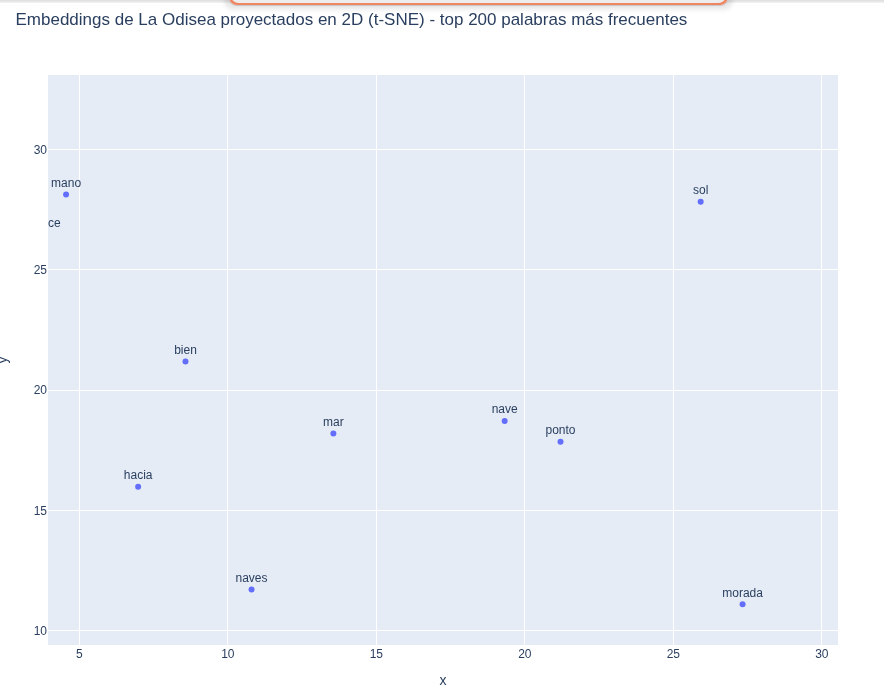
- **itaca - patria**: dos palabras que significaban lo mismo para el protagonista.
- **Dioses - inmortales**: sinonimos
- **dios - jupiter**: jupiter era un dios y de los más importantes.
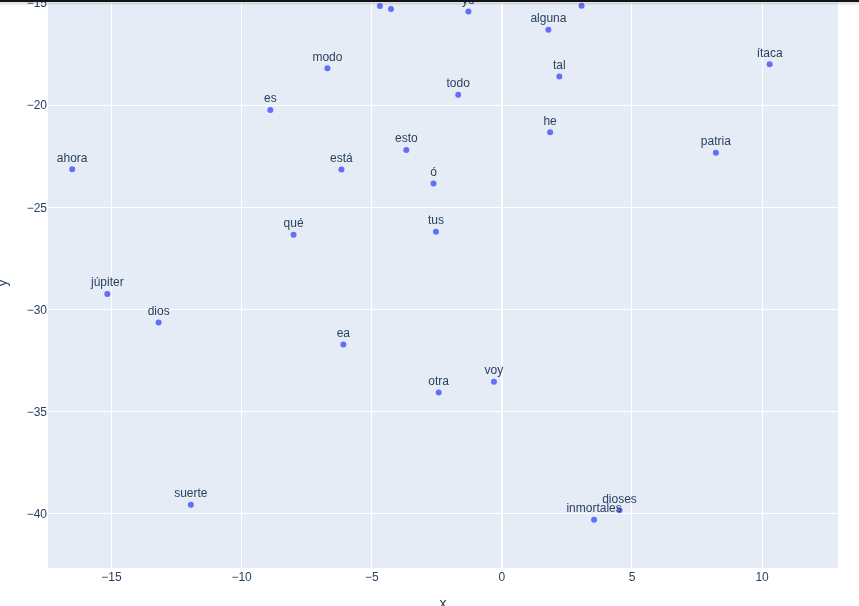
- **Conectores del lengujes**: las `stopwords` y conectores del lenguaje se encuentran juntas en un grupo.
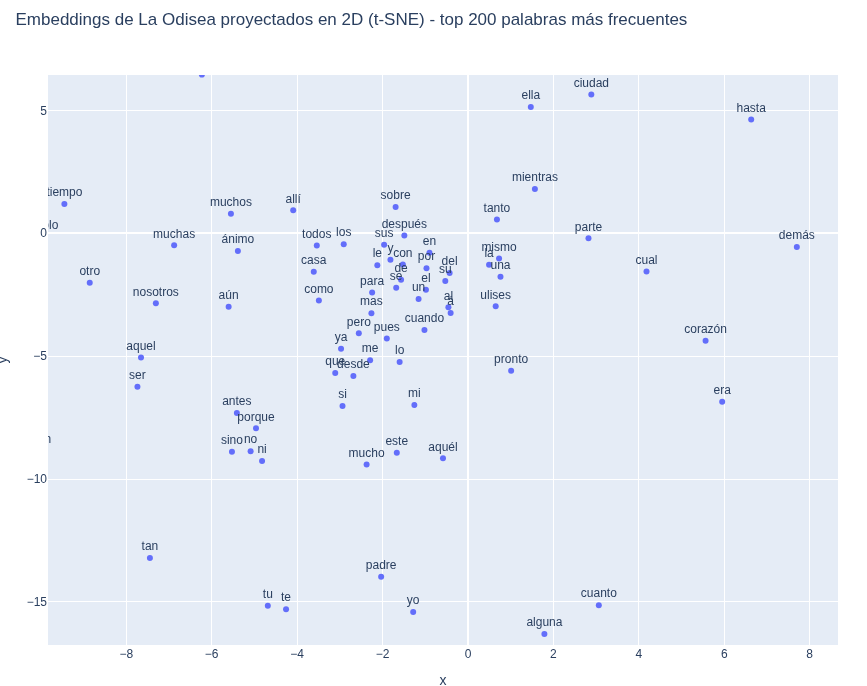

In [49]:
# Guardamos los vectores y etiquetas como .tsv para explorar en
# http://projector.tensorflow.org/
vectors = np.asarray(w2v_model.wv.vectors)
labels_all = list(w2v_model.wv.index_to_key)

np.savetxt("vectors.tsv", vectors, delimiter="\t")

with open("labels.tsv", "w") as fp:
    for item in labels_all:
        fp.write("%s\n" % item)

print("Archivos vectors.tsv y labels.tsv generados.")

Archivos vectors.tsv y labels.tsv generados.


### Conclusiones

- Usar un libro completo como corpus (en este caso, "La Odisea" descargada de Project Gutenberg) en lugar de un cancionero chico mejora notoriamente la calidad de los embeddings obtenidos: el vocabulario que más similitud mostró con términos de interés (`mar`, `ulises`, `dioses`) resultó temáticamente coherente en casi todos los casos, algo que no sucedía de forma tan consistente con el corpus de canciones de un desafío anterior.
- El tokenizador `text_to_word_sequence` de `tensorflow.keras` no obtiene palabras no limpias como `«¡huésped`, `«¡padre` o `«yo`.
- Se probo distintas configuraciones de hiperparametros para el modelo y la mejor, en general, fue de `min_count=5`, `window=5`, `vector_size=150`, `negative=10`, `sg=1`, pero en todas habia ajustes que para ciertos agrupamientos de parametros eran mejores. Esto confirma que, con un corpus de este tamaño (~119 mil tokens), pequeños ajustes de hiperparámetros reordenan el espacio de embeddings de forma no uniforme: fortalecen algunas relaciones semánticas y debilitan otras, sin que exista una combinación que optimice todo a la vez.
- La proyección con t-SNE a 2D es útil para detectar agrupamientos cualitativos, pero conviene siempre verificar con la distancia real entre los puntos antes de sacar conclusiones a partir de lo que parece cercano a simple vista..
- En suma, el tamaño y la calidad gramatical del corpus (oraciones completas de prosa narrativa vs. líneas sueltas de canciones) sigue siendo el factor más determinante en la calidad final de los embeddings, por encima de ajustes más finos de tokenización o hiperparámetros.